# S01 · 数据审计与时间序列的坑

> **Day 1 / 14** ｜ 对应论文章节 **3.1–3.2（Data and Quality Control）**
>
> ⚠️ 本手册全程使用**模拟数据**。所有数值只用于验证流程是否跑通，**不是科学结论**。

---

## 学习目标

- 说清楚为什么「数据审计」必须排在「分析」之前
- 识别原始气象数据里的 4 类陷阱：缺测编码、物理不一致、时间口径、单位
- 用 R 做一份可写进论文的质控报告
- 解释时间序列的三个性质（季节性 / 自相关 / 非平稳）分别会破坏哪一步分析

---

## 1. 为什么第一步不是分析

审稿人最常写的一句话是：

> *"The results are likely an artefact of data quality issues that were not addressed."*

气象数据里有四类问题，每一类都能让结论彻底反转：

| 问题 | 后果 | 本讲的处理 |
|---|---|---|
| **缺测编码**（`-999`、`9999`、空白） | 被当成极端值 → 阈值虚高 / 事件虚增 | 统一转 `NA` |
| **物理不一致**（Tmax < Tmin） | 事件定义失效 | 反序时两侧置 `NA` |
| **时间口径**（0800–0800 vs 0000–2400） | 降雨与温度错位 8 小时 → ARP 全错 | 必须向数据方书面确认 |
| **单位**（°C / K、mm / 0.1mm、RH 0–1 / 0–100） | 阈值、湿球、降水全部错 | 用物理边界检查兜底 |

---

## 2. 加载共享模块

In [1]:
# 自动定位 00_setup.R：无论 Jupyter 的工作目录是 method_manual/ 还是 notebooks/ 都能跑
for (p in c("00_setup.R", "notebooks/00_setup.R", "../00_setup.R")) {
  if (file.exists(p)) { source(p); break }
}

# 确认关键参数
str(CFG)


[00_setup.R] 已加载
  项目根目录 : C:/Users/User/Desktop/Jz/UTM/UGRP
  基准期     : 1985-2014
  阈值       : 90百分位, ±7天滑窗
  事件规则   : 最短 3 天, 合并间隔 ≤ 2 天
  干/湿切点  : ARP < 30 / > 50


List of 13
 $ base_years  : int [1:30] 1985 1986 1987 1988 1989 1990 1991 1992 1993 1994 ...
 $ halfwin     : num 7
 $ prob_default: num 0.9
 $ min_obs     : num 50
 $ min_len     : num 3
 $ max_gap     : num 2
 $ arp_window  : num 7
 $ arp_dry     : num 30
 $ arp_wet     : num 50
 $ min_n_copula: num 30
 $ n_boot      : num 1000
 $ boot_seed   : num 11
 $ seed        : num 20260101


---

## 3. 原始数据长什么样

In [2]:
raw_files <- list.files(PATHS$raw, pattern = "\\.csv$", full.names = TRUE)
raw_files <- raw_files[!grepl("stations_meta", raw_files)]

cat("站点数:", length(raw_files), "\n")

站点数: 10 


In [3]:
raw1 <- read_raw_station(raw_files[1])
cat("维度:", dim(raw1), "\n")
head(raw1, 3)

维度: 16060 6 


,station,date,tmax,tmin,rain,rh
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,Alor_Star,1980-01-01,32.4,25.6,6.7,79.5
2,Alor_Star,1980-01-02,32.6,24.5,0.0,84.3
3,Alor_Star,1980-01-03,32.4,29.1,0.0,77.7


In [4]:
summary(raw1[, c("tmax", "tmin", "rain", "rh")])

      tmax              tmin            rain              rh       
 Min.   :-999.00   Min.   :20.90   Min.   : 0.000   Min.   :66.60  
 1st Qu.:  32.70   1st Qu.:26.00   1st Qu.: 0.000   1st Qu.:80.10  
 Median :  33.70   Median :27.20   Median : 0.000   Median :82.90  
 Mean   :  23.43   Mean   :27.28   Mean   : 4.754   Mean   :82.88  
 3rd Qu.:  34.70   3rd Qu.:28.50   3rd Qu.: 5.800   3rd Qu.:85.80  
 Max.   :  39.40   Max.   :34.80   Max.   :93.500   Max.   :99.00  

> 💡 **看 `Min.` 那一行。** 如果出现 `-999`，说明缺测值是以哨兵值（sentinel value）形式存储的——它会被 R 当成真实温度参与计算。

---

## 4. 缺测编码：`-999` 是一个温度吗？

In [5]:
sentinels <- sapply(raw1[, c("tmax", "tmin", "rain", "rh")],
                    function(x) sum(x == -999, na.rm = TRUE))
print(sentinels)
cat("\n占全部记录的比例:", round(sentinels["tmax"] / nrow(raw1) * 100, 2), "%\n")

tmax tmin rain   rh 
 161    0    0    0 



占全部记录的比例: 1 %


### 4.1 破坏力取决于你在看分布的哪个位置

In [6]:
contaminated <- raw1$tmax
cleaned      <- dplyr::na_if(raw1$tmax, -999)

cmp <- data.frame(
  statistic   = c("mean", "10th pct", "50th pct", "90th pct"),
  contaminated = c(mean(contaminated),
                   quantile(contaminated, 0.10),
                   quantile(contaminated, 0.50),
                   quantile(contaminated, 0.90)),
  cleaned      = c(mean(cleaned, na.rm = TRUE),
                   quantile(cleaned, 0.10, na.rm = TRUE),
                   quantile(cleaned, 0.50, na.rm = TRUE),
                   quantile(cleaned, 0.90, na.rm = TRUE))
)
cmp$bias <- round(cmp$cleaned - cmp$contaminated, 2)
print(cmp)

    statistic contaminated  cleaned  bias
         mean     23.42767 33.78121 10.35
10%  10th pct     31.90000 31.90000  0.00
50%  50th pct     33.70000 33.70000  0.00
90%  90th pct     35.80000 35.80000  0.00


In [7]:
# 顺带一个 R 的坑：cat() 不调用 Date 的格式化方法
cat(min(as.Date("2020-05-01")), "\n")           # 打印 18383，不是日期
cat(format(min(as.Date("2020-05-01"))), "\n")   # 正确

18383 


2020-05-01 


> 🔍 **注意 `90th pct` 那一行的 bias = 0。**
>
> 这不是好消息，这是**最危险的情况**：因为缺测只占 1%，90 百分位恰好落在不受污染的位置。于是你会得出「数据没问题」的结论，然后一路错下去。
>
> 如果缺测率是 15%（很常见），同一条 90 百分位阈值就会偏移 —— 见下一格，重点看偏移如何被放大成事件数的变化。

### 4.2 缺测率升高后，阈值立刻塌掉

In [8]:
set.seed(1)
heavy <- contaminated
idx   <- sample(length(heavy), size = round(0.15 * length(heavy)))
heavy[idx] <- -999

q_wrong <- quantile(heavy, 0.90)
q_right <- quantile(heavy[-idx], 0.90)

cat(sprintf("缺测率 15%% 时——\n"))
cat(sprintf("  未处理 -999 的 90 百分位: %.2f degC\n", q_wrong))
cat(sprintf("  正确处理后的 90 百分位:   %.2f degC\n", q_right))
cat(sprintf("  阈值偏移: %.2f degC\n", q_right - q_wrong))

n_wrong <- sum(heavy > q_wrong, na.rm = TRUE)
n_right <- sum(heavy[-idx] > q_right, na.rm = TRUE)
cat(sprintf("  超阈值天数: 用错阈值 %d 天 vs 正确 %d 天  (%+.0f%%)\n",
            n_wrong, n_right, (n_wrong / n_right - 1) * 100))

缺测率 15% 时——


  未处理 -999 的 90 百分位: 35.60 degC


  正确处理后的 90 百分位:   35.80 degC


  阈值偏移: 0.20 degC


  超阈值天数: 用错阈值 1569 天 vs 正确 1278 天  (+23%)


> ⚠️ **这就是「垃圾进、垃圾出」的具体形态。** 注意最后一行：阈值只偏移了零点几度，但**超阈值天数变化的比例远大于此**。原因是热带气温分布很窄（日际标准差约 1 °C），阈值附近的概率密度很高，微小偏移会放大成可观的事件数变化。
>
> 关键教训：**不能靠"结果看起来合理"来判断数据干净**。必须显式检查缺测率，并用 `summary()` 看 `Min.` 是否是哨兵值。

---

## 5. 物理一致性检查

质控函数在 `00_setup.R` 里，这里逐步验证它的每一步。

In [9]:
clean1 <- qc_one_station(raw1)

qc <- attr(clean1, "qc")
print(qc)

cat("\n--- 解释 ---\n")
cat("rows_in   : 原始行数\n")
cat("miss_code : 被识别为缺测编码的单元格数\n")
cat("dup       : 重复日期的行数\n")
cat("range     : 超出物理范围（温度 -20~50 degC，RH 0~100%）的单元格数\n")
cat("neg_rain  : 负降雨单元格数\n")
cat("order_bad : Tmax < Tmin 的行数\n")

  rows_in miss_code       dup     range  neg_rain order_bad 
    16060       161         0         0         0         0 



--- 解释 ---


rows_in   : 原始行数


miss_code : 被识别为缺测编码的单元格数


dup       : 重复日期的行数


range     : 超出物理范围（温度 -20~50 degC，RH 0~100%）的单元格数


neg_rain  : 负降雨单元格数


order_bad : Tmax < Tmin 的行数


In [10]:
# 质控后的物理边界是否干净？
summary(clean1[, c("tmax", "tmin", "rain", "rh", "twmax")])

      tmax            tmin            rain              rh       
 Min.   :29.10   Min.   :20.90   Min.   : 0.000   Min.   :66.60  
 1st Qu.:32.70   1st Qu.:26.00   1st Qu.: 0.000   1st Qu.:80.10  
 Median :33.70   Median :27.20   Median : 0.000   Median :82.90  
 Mean   :33.78   Mean   :27.28   Mean   : 4.754   Mean   :82.88  
 3rd Qu.:34.70   3rd Qu.:28.50   3rd Qu.: 5.800   3rd Qu.:85.80  
 Max.   :39.40   Max.   :34.80   Max.   :93.500   Max.   :99.00  
 NAs    :161                                                     
     twmax      
 Min.   :25.49  
 1st Qu.:30.08  
 Median :31.13  
 Mean   :31.22  
 3rd Qu.:32.26  
 Max.   :37.77  
 NAs    :161    

In [11]:
# 湿球必须 <= 干球，这是物理定律，不是经验规则
viol <- sum(clean1$twmax > clean1$tmax + 0.05, na.rm = TRUE)
cat("Twmax > Tmax 的日数:", viol, "  (应为 0)\n")

Twmax > Tmax 的日数: 0   (应为 0)


---

## 6. 构建全站清洗数据

In [12]:
d <- build_clean_daily(force = TRUE)

cat("行数:", nrow(d), "\n")
cat("站点:", length(unique(d$station)), "\n")
cat("时段:", format(min(d$date)), "~", format(max(d$date)), "\n")
cat("列:", paste(names(d), collapse = ", "), "\n")

行数: 160600 


站点: 10 


时段: 1980-01-01 ~ 2023-12-31 


列: station, date, tmax, tmin, rain, rh, twmax 


In [13]:
# 质控汇总表
qc_tab <- read.csv(file.path(PATHS$mres, "qc_summary.csv"))
print(qc_tab)

             station rows_in miss_code dup range neg_rain order_bad
1          Alor_Star   16060       161   0     0        0         0
2        Bayan_Lepas   16060       161   0     0        0         0
3  Cameron_Highlands   16060       161   0     0        0         0
4            Chuping   16060       161   0     0        0         0
5               Ipoh   16060       161   0     0        0         0
6             Kluang   16060       161   0     0        0         0
7         Kota_Bharu   16060       161   0     0        0         0
8         Kuala_Krai   16060       161   0     0        0         0
9            Kuantan   16060       161   0     0        0         0
10          Langkawi   16060       161   0     0        0         0


---

## 7. 时间序列的三个性质

这三个性质不是「顺便看看」，它们各自会破坏后面某一步分析：

| 性质 | 破坏什么 | 应对 |
|---|---|---|
| **季节性** | 直接算全年分位数 → 夏季虚假事件暴增 | 按日历日滑动窗（S02） |
| **自相关** | 事件不独立 → 有效样本量远小于名义样本量 | declustering（S03）+ block bootstrap（S11） |
| **非平稳** | 固定阈值 → 后期事件数系统性偏多 | 敏感性分析（S14） |

### 7.1 季节性

Warning message:
"Removed 161 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


Warning message:
"Removed 161 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


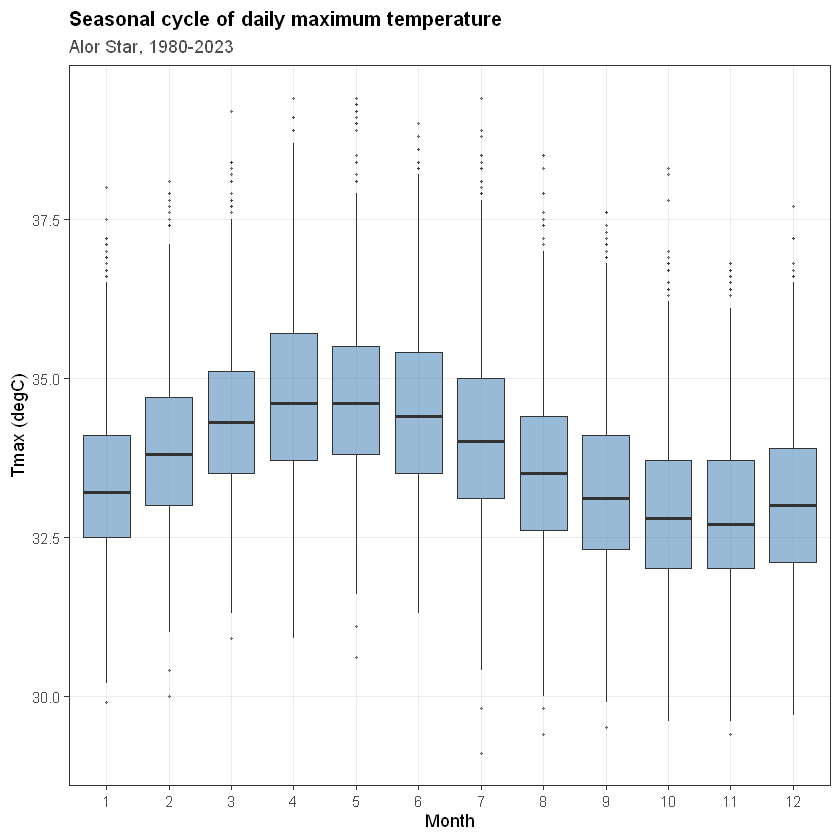

In [14]:
p_season <- d %>%
  filter(station == "Alor_Star") %>%
  mutate(month = factor(lubridate::month(date))) %>%
  ggplot(aes(month, tmax)) +
  geom_boxplot(fill = "steelblue", alpha = 0.55, outlier.size = 0.5) +
  labs(x = "Month", y = "Tmax (degC)",
       title = "Seasonal cycle of daily maximum temperature",
       subtitle = "Alor Star, 1980-2023") +
  theme_paper()

save_fig(p_season, "S01_seasonal_cycle", 6.5, 4)
p_season

> 📌 马来西亚的年温差很小（约 2 °C），但**季节循环的相位**很重要：如果阈值不分季节，你的事件会集中在 3–5 月。

### 7.2 自相关

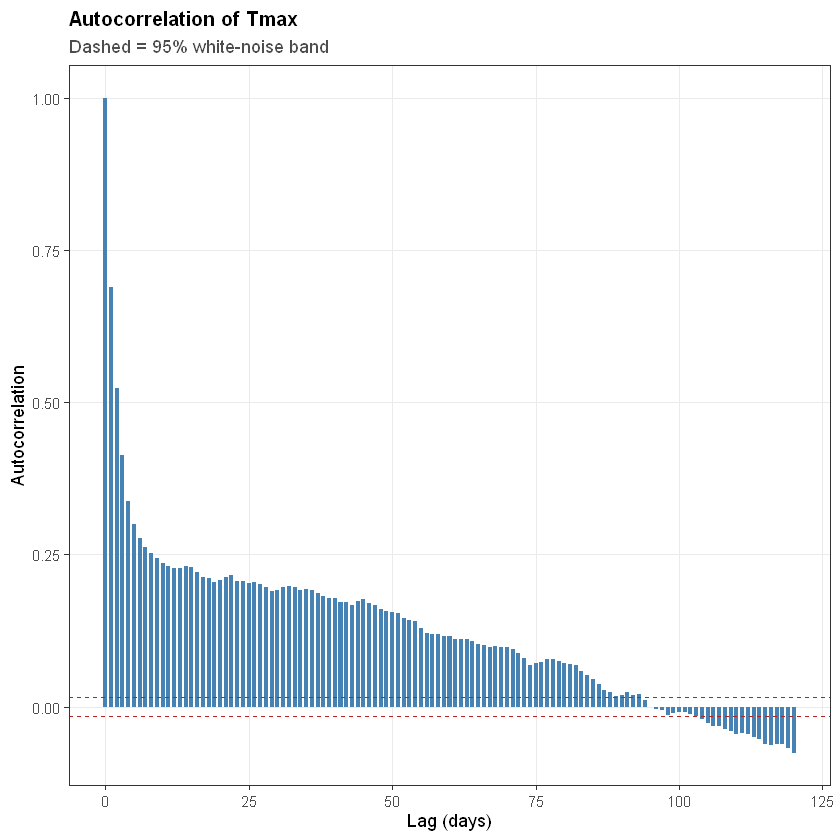

In [15]:
x <- d %>% filter(station == "Alor_Star") %>% arrange(date) %>% pull(tmax)

# stats::acf() 遇到 NA 会整列返回 NA（它基于 FFT，无法跳过缺失）。
# 正确做法：按"成对完整观测"计算自相关，这等价于 AR 模型的成对似然。
acf_pairwise <- function(v, lag.max = 120, min_obs = 30) {
  n <- length(v)
  sapply(0:lag.max, function(k) {
    a <- v[(k + 1):n]; b <- v[1:(n - k)]
    ok <- !is.na(a) & !is.na(b)
    if (sum(ok) < min_obs) return(NA_real_)
    cor(a[ok], b[ok])
  })
}

df_ac <- data.frame(lag = 0:120, acf = acf_pairwise(x, 120))

p_acf <- ggplot(df_ac, aes(lag, acf)) +
  geom_col(width = 0.7, fill = "steelblue") +
  geom_hline(yintercept = c(-1, 1) * 1.96 / sqrt(sum(!is.na(x))),
             linetype = "dashed", colour = "firebrick") +
  labs(x = "Lag (days)", y = "Autocorrelation",
       title = "Autocorrelation of Tmax",
       subtitle = "Dashed = 95% white-noise band") +
  theme_paper()

save_fig(p_acf, "S01_acf", 6.5, 4)
p_acf

> 📌 **这张图决定了你的统计推断能不能用教科书公式。** 日气温的自相关在 1 天滞后处通常在 0.7 以上，这意味着 44 年 × 365 天 ≈ 16,000 个观测的**有效样本量只有几百**。任何忽略了这一点的 p 值都是虚假的。

In [16]:
# 一阶自回归系数（AR(1)）
ar1 <- coef(lm(x[-1] ~ x[-length(x)]))[2]
cat("AR(1) coefficient =", round(ar1, 3), "\n")
cat("有效样本量 ≈ N * (1 - ar1) / (1 + ar1) =",
    round(sum(!is.na(x)) * (1 - ar1) / (1 + ar1)), "\n")

AR(1) coefficient = 0.69 


有效样本量 ≈ N * (1 - ar1) / (1 + ar1) = 2920 


### 7.3 非平稳（趋势）

In [17]:
z  <- d %>% filter(station == "Alor_Star") %>% arrange(date)
tt <- as.numeric(z$date - min(z$date)) / 365.25     # 年

trend_per_decade <- coef(lm(z$tmax ~ tt))[2] * 10
cat(sprintf("Tmax 线性趋势 = %.3f degC / decade\n", trend_per_decade))

Tmax 线性趋势 = 0.167 degC / decade


`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


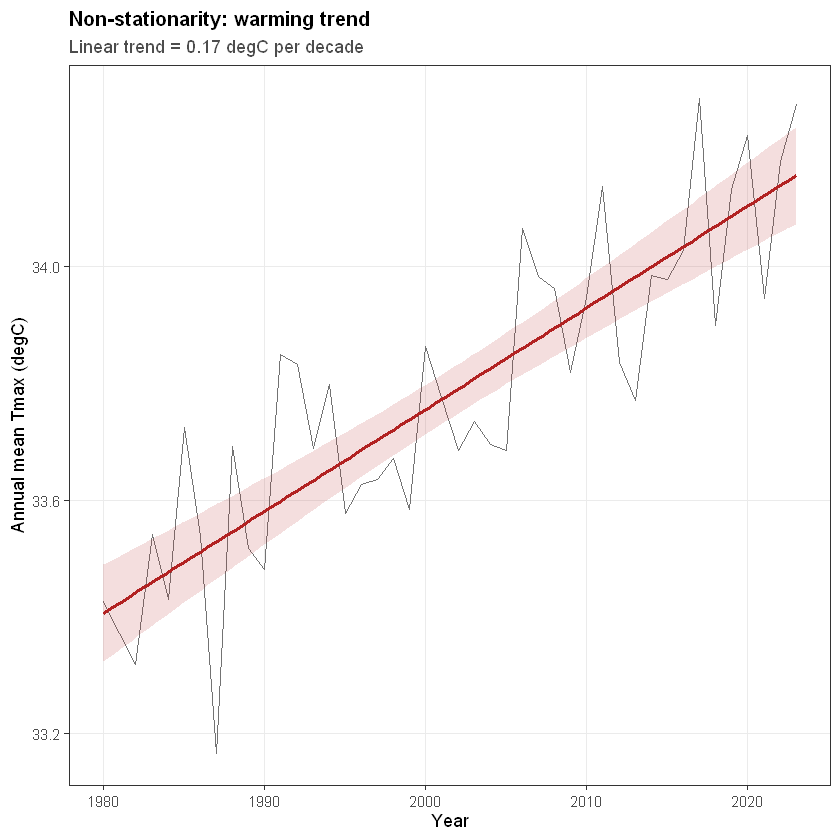

In [18]:
p_trend <- z %>%
  mutate(year = lubridate::year(date)) %>%
  group_by(year) %>%
  summarise(annual_mean = mean(tmax, na.rm = TRUE), .groups = "drop") %>%
  ggplot(aes(year, annual_mean)) +
  geom_line(colour = "grey45") +
  geom_smooth(method = "lm", se = TRUE, colour = "firebrick", fill = "firebrick", alpha = 0.15) +
  labs(x = "Year", y = "Annual mean Tmax (degC)",
       title = "Non-stationarity: warming trend",
       subtitle = sprintf("Linear trend = %.2f degC per decade", trend_per_decade)) +
  theme_paper()

save_fig(p_trend, "S01_trend", 6.5, 4)
p_trend

> ⚠️ 趋势存在意味着 **「1980 年代的事件」和「2020 年代的事件」不是同一个总体**。固定基准期阈值会系统性地让后期事件变多。这不是气候变化信号，是口径造成的伪信号。S14 会做时变阈值的敏感性分析。

---

## 8. 缺测的时空分布

缺测**不是随机**的——如果夏季缺测更多，事件数就会被系统性低估。

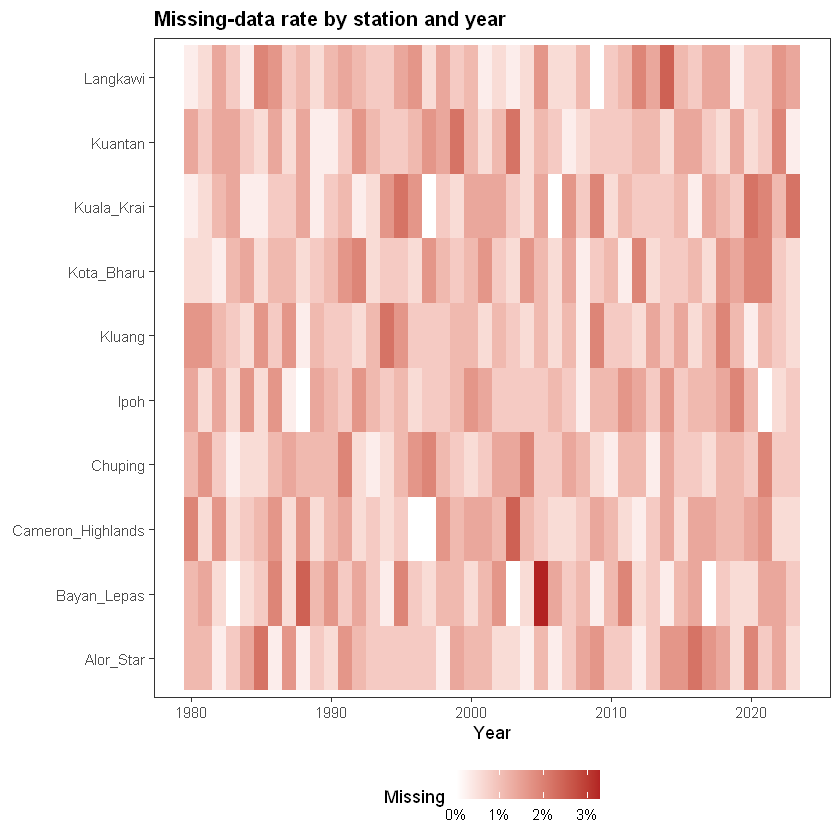

In [19]:
miss <- d %>%
  mutate(year = lubridate::year(date)) %>%
  group_by(station, year) %>%
  summarise(miss_rate = mean(is.na(tmax)), .groups = "drop")

p_miss <- ggplot(miss, aes(year, station, fill = miss_rate)) +
  geom_tile() +
  scale_fill_gradient(low = "white", high = "firebrick",
                      labels = scales::percent, name = "Missing") +
  labs(x = "Year", y = NULL, title = "Missing-data rate by station and year") +
  theme_paper() +
  theme(panel.grid = element_blank())

save_fig(p_miss, "S01_missing_map", 7, 4.5)
p_miss

In [20]:
# 缺测率是否有季节结构？
d %>%
  mutate(month = lubridate::month(date)) %>%
  group_by(month) %>%
  summarise(miss_rate = mean(is.na(tmax)), .groups = "drop") %>%
  print()

# A tibble: 12 × 2
   month miss_rate
   <dbl>     <dbl>
 1     1   0.00916
 2     2   0.00901
 3     3   0.0109 
 4     4   0.0104 
 5     5   0.0104 
 6     6   0.00977
 7     7   0.0102 
 8     8   0.0103 
 9     9   0.0116 
10    10   0.00872
11    11   0.0118 
12    12   0.00799


> 📌 如果 6–9 月缺测率明显偏高，就必须在方法章写明**缺测非随机**，并做敏感性分析（只保留完整年份重跑）。

---

## 9. 本讲产出

In [21]:
cat("产出文件：\n")
cat("  ", file.path(PATHS$clean, "clean_daily.csv"), "\n")
cat("  ", file.path(PATHS$mres,  "qc_summary.csv"), "\n")
cat("  ", file.path(PATHS$mfig,  "S01_seasonal_cycle.png"), "\n")
cat("  ", file.path(PATHS$mfig,  "S01_acf.png"), "\n")
cat("  ", file.path(PATHS$mfig,  "S01_trend.png"), "\n")
cat("  ", file.path(PATHS$mfig,  "S01_missing_map.png"), "\n")

产出文件：


   C:/Users/User/Desktop/Jz/UTM/UGRP/03_clean/clean_daily.csv 


   C:/Users/User/Desktop/Jz/UTM/UGRP/method_manual/results/qc_summary.csv 


   C:/Users/User/Desktop/Jz/UTM/UGRP/method_manual/figs/S01_seasonal_cycle.png 


   C:/Users/User/Desktop/Jz/UTM/UGRP/method_manual/figs/S01_acf.png 


   C:/Users/User/Desktop/Jz/UTM/UGRP/method_manual/figs/S01_trend.png 


   C:/Users/User/Desktop/Jz/UTM/UGRP/method_manual/figs/S01_missing_map.png 


---

## 10. 常见错误

| 错误 | 后果 | 正确做法 |
|---|---|---|
| 用 `na.omit()` 直接删行 | 破坏时间连续性，事件被切断 | 保留行、让 `NA` 参与游程判定 |
| 用全年分位数做阈值 | 夏季事件虚增 | 日历日 ±7 天滑动窗 |
| 忽略 AR(1) 做显著性检验 | p 值严重偏小 | block bootstrap / 置换检验 |
| 缺测率不报告 | 审稿人质疑选择性 | 出时空分布图 |

---

## 11. 自检问题

<details>
<summary>Q1：为什么 `-999` 比 `NA` 更危险？</summary>

因为 `NA` 会被 R 的统计函数自动跳过（配合 `na.rm = TRUE`），而 `-999` 是一个**合法的数值**，会静默参与所有计算。它会让均值、分位数、游程判定全部出错，而且不报任何错。
</details>

<details>
<summary>Q2：AR(1) = 0.75 时，16,000 个观测的有效样本量是多少？为什么这很重要？</summary>

有效样本量 ≈ N × (1−r)/(1+r) = 16000 × 0.25/1.75 ≈ 2,286。重要性在于：所有基于独立样本的置信区间和 p 值都会**高估精度约 7 倍**。这就是为什么 S11 必须用 bootstrap 而不是教科书公式。
</details>

<details>
<summary>Q3：如果降雨按 0800–0800 统计，温度按 0000–2400 统计，会出什么问题？</summary>

ARP 用的是「事件开始前 7 天」的降雨。如果两者的「日」边界差 8 小时，前 7 天的降雨窗口就整体错位了 8 小时，可能把热浪当天下午的降雨算成「前期降雨」，直接污染干湿分层。必须向数据方确认口径，必要时平移降雨序列。
</details>

<details>
<summary>Q4：为什么湿球温度必须 ≤ 干球温度？</summary>

湿球是「水蒸发冷却能达到的最低温度」，最多只能降到与空气同温（饱和时两者相等）。所以 Tw ≤ T 是热力学约束。若违反，说明公式用错（最常见是 RH 用了 0–1 而不是 0–100）。
</details>

<details>
<summary>Q5：趋势存在时，为什么不能直接说「后期热浪更多是气候变化」？</summary>

因为阈值用的是固定基准期（1985–2014）。后期整体升温后，超过这条固定线的天数自然变多，即使气候没有变化也会如此。要区分「气候信号」和「口径伪信号」，必须做时变阈值的对照分析。
</details>

---

## 下一步

**S02 · 阈值法**：把「按日历日算百分位」这件事拆开，看清楚 ±7 天窗口、`type = 8` 分位数、基准期选择分别起什么作用。